### 1. Build a Basic Chatbot Using Ollama
### 2. Implement Checkpointer, Thread, and Persistence in the Chatbot

In [70]:
#Define Library
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
#Saving data in memory
#from langgraph.checkpoint.memory import MemorySaver

In [71]:
##########local ollama
from langchain_ollama import ChatOllama
model = ChatOllama(model="gemma3:4b")
response = model.invoke("the capital of India? in one word")
print(response.content)

Delhi


In [72]:
#Define State
class llm_state(TypedDict):
    question: str
    answer: str

In [73]:
def llm_qa(state:llm_state) -> llm_state:
    question = state['question']
    answer = model.invoke(question)
    #update state
    state['answer']=answer

    return state

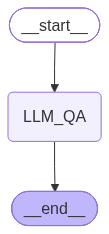

In [74]:
#Define graph
graph=StateGraph(llm_state) #create object for graph

#add notes to the graph
#Create a node called calculate_bmi and execute the calculate_bmi function when this node runs.
graph.add_node('LLM_QA',llm_qa)

#add edges to the graph
graph.add_edge(START,'LLM_QA')
graph.add_edge('LLM_QA',END)

#compile the graph
workflow=graph.compile()
workflow


In [75]:
#execute the graph
initial_state = {'question':"Capital of United State"}
final_state=workflow.invoke(initial_state)
print(final_state['answer'])

content='The capital of the United States is **Washington, D.C.** \n\nIt stands for District of Columbia. \n\nDo you want to know anything more about Washington, D.C. or the United States government?' additional_kwargs={} response_metadata={'model': 'gemma3:4b', 'created_at': '2026-10-11T13:48:07.1695Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1117436000, 'load_duration': 3708042, 'prompt_eval_count': 14, 'prompt_eval_duration': 135564000, 'eval_count': 46, 'eval_duration': 974564000, 'logprobs': None, 'model_name': 'gemma3:4b', 'model_provider': 'ollama'} id='lc_run--01a12b38-8222-7622-8b3a-62241f2de9e1-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 14, 'output_tokens': 46, 'total_tokens': 60}


In [76]:
print(final_state['answer'].content)

The capital of the United States is **Washington, D.C.** 

It stands for District of Columbia. 

Do you want to know anything more about Washington, D.C. or the United States government?


In [77]:
while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
        break   

    response=workflow.invoke({ "question": [HumanMessage(content=user_message)]})
    print('AI :' ,response['answer'].content)

Type here :  hi


User : hi
AI : Hi there! How's your day going so far? 😊 

Is there anything you'd like to chat about, or were you just saying hello?


Type here :  my name is shashi


User : my name is shashi
AI : Hi Shashi! It's nice to meet you. 😊 

Is there anything you'd like to chat about or anything I can help you with today?


Type here :  can you tell me my name


User : can you tell me my name
AI : I have no way of knowing your name! As an AI, I don't have access to personal information unless you tell me. 😊 

You'll have to tell me your name!



Type here :  bye


User : bye


# Checkpointer, Thread, and Persistence in LangGraph

## 1. What is a Checkpointer?

A **Checkpointer saves the state** of a LangGraph workflow.

**Example:**
```python
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
workflow = graph.compile(checkpointer=checkpointer)
```

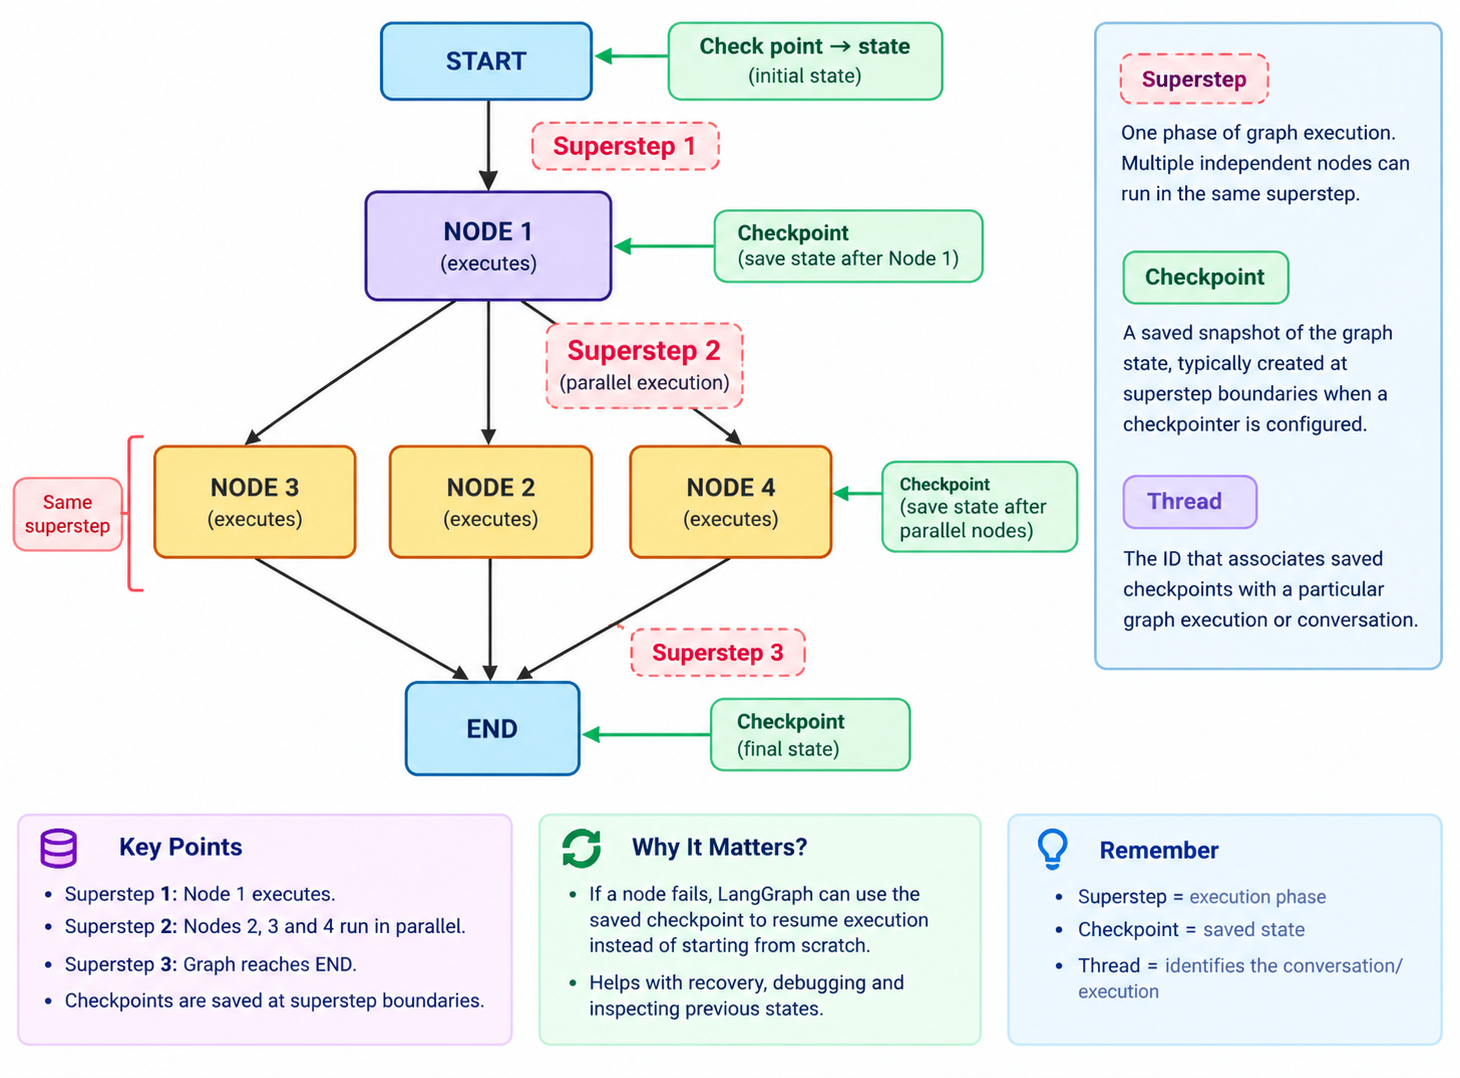

In [37]:
from IPython.display import Image
Image(filename="checkpointer.png")

## 2. What is a Thread?

A **Thread is a unique ID for a conversation**.

**Example:**
```python
config = {
    "configurable": {
        "thread_id": "user_101"
    }
}
```

- `user_101` identifies one conversation.
- `user_102` identifies another conversation.

## 3. What is Persistence?

**Persistence means saving data so it can be used later.**

For example, a chatbot can save its conversation state and continue later.

## 4. How Do They Work Together?

1. The user asks a question.
2. LangGraph processes the question.
3. The checkpointer saves the workflow state.
4. The thread ID identifies the conversation.
5. The next message with the same thread ID can continue from the saved state.

## 5. Simple Real-Life Example

Imagine a notebook:

- **Persistence:** Saving your notes for later.
- **Checkpointer:** The mechanism that saves your notes.
- **Thread:** The label on the notebook identifying whose conversation it belongs to.

## 6. Important Points

- Use the same `thread_id` to continue a conversation.
- Use a different `thread_id` for a new conversation.
- `MemorySaver()` stores data temporarily in memory.
- Use a database-backed checkpointer to retain saved state after the application restarts.

**In one line:**

**Persistence = Save for later | Checkpointer = Saves the state | Thread = Identifies the conversation.**

In [78]:
#Saving data in memory
from langgraph.checkpoint.memory import MemorySaver
#create checkpoint for data saving
checkpointer = MemorySaver()
# Compile graph with checkpointer
workflow=graph.compile(checkpointer=checkpointer)


In [80]:
thread_id='1'
while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
        break   

    # Define a thread
    config= {'configurable' :{'thread_id':thread_id}}
    # interaction in the same thread
    #response=workflow.invoke({ "question": [HumanMessage(content=user_message)]})
    response=workflow.invoke({ "question": [HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['answer'].content)

Type here :  bye


User : bye


In [81]:
#workflow.get_state(config) retrieves the latest saved state of a graph for a specific thread.
workflow.get_state(config)

StateSnapshot(values={'question': [HumanMessage(content='can you tell me my name', additional_kwargs={}, response_metadata={})], 'answer': AIMessage(content='I do not know your name. As an AI, I have no way of knowing personal information about you unless you tell me. \n\nCould you tell me your name? 😊', additional_kwargs={}, response_metadata={'model': 'gemma3:4b', 'created_at': '2026-10-11T13:49:38.700244Z', 'done': True, 'done_reason': 'stop', 'total_duration': 859287166, 'load_duration': 7441666, 'prompt_eval_count': 16, 'prompt_eval_duration': 67105999, 'eval_count': 37, 'eval_duration': 779867000, 'logprobs': None, 'model_name': 'gemma3:4b', 'model_provider': 'ollama'}, id='lc_run--01a12b39-e8af-7651-8a0c-2ffbe73c246a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 37, 'total_tokens': 53})}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c57a9-a15f-67ca-8007-197a431d6b5b'}}, metadata={'s

In [82]:
#get_state_history() is used to retrieve the history of saved checkpoints for a particular thread. 
#It helps inspect how the graph's state changed during execution and show intermediate checkpoint values.
list(workflow.get_state_history(config))

[StateSnapshot(values={'question': [HumanMessage(content='can you tell me my name', additional_kwargs={}, response_metadata={})], 'answer': AIMessage(content='I do not know your name. As an AI, I have no way of knowing personal information about you unless you tell me. \n\nCould you tell me your name? 😊', additional_kwargs={}, response_metadata={'model': 'gemma3:4b', 'created_at': '2026-10-11T13:49:38.700244Z', 'done': True, 'done_reason': 'stop', 'total_duration': 859287166, 'load_duration': 7441666, 'prompt_eval_count': 16, 'prompt_eval_duration': 67105999, 'eval_count': 37, 'eval_duration': 779867000, 'logprobs': None, 'model_name': 'gemma3:4b', 'model_provider': 'ollama'}, id='lc_run--01a12b39-e8af-7651-8a0c-2ffbe73c246a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 16, 'output_tokens': 37, 'total_tokens': 53})}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c57a9-a15f-67ca-8007-197a431d6b5b'}}, metadata={'

In [83]:
    config2= {'configurable' :{'thread_id':"thread_2"}}
    workflow.invoke({ "question": [HumanMessage(content="apple in one sentence")]},config=config2)

{'question': [HumanMessage(content='apple in one sentence', additional_kwargs={}, response_metadata={})],
 'answer': AIMessage(content='An apple is a crisp, juicy fruit known for its sweetness and nutritional value.', additional_kwargs={}, response_metadata={'model': 'gemma3:4b', 'created_at': '2026-10-11T13:56:40.489079Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1836939542, 'load_duration': 1342950792, 'prompt_eval_count': 14, 'prompt_eval_duration': 139970000, 'eval_count': 17, 'eval_duration': 351525000, 'logprobs': None, 'model_name': 'gemma3:4b', 'model_provider': 'ollama'}, id='lc_run--01a12b40-5479-79b3-bd26-145eff7fe1cb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 17, 'total_tokens': 31})}

In [84]:
#workflow.get_state(config) retrieves the latest saved state of a graph for a specific thread.
workflow.get_state(config2)

StateSnapshot(values={'question': [HumanMessage(content='apple in one sentence', additional_kwargs={}, response_metadata={})], 'answer': AIMessage(content='An apple is a crisp, juicy fruit known for its sweetness and nutritional value.', additional_kwargs={}, response_metadata={'model': 'gemma3:4b', 'created_at': '2026-10-11T13:56:40.489079Z', 'done': True, 'done_reason': 'stop', 'total_duration': 1836939542, 'load_duration': 1342950792, 'prompt_eval_count': 14, 'prompt_eval_duration': 139970000, 'eval_count': 17, 'eval_duration': 351525000, 'logprobs': None, 'model_name': 'gemma3:4b', 'model_provider': 'ollama'}, id='lc_run--01a12b40-5479-79b3-bd26-145eff7fe1cb-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 17, 'total_tokens': 31})}, next=(), config={'configurable': {'thread_id': 'thread_2', 'checkpoint_ns': '', 'checkpoint_id': '1f1c57b9-57dd-6ef2-8001-2bc9019a2222'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2

In [ ]:
#Define Library
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph.message import add_messages
#Saving data in memory
from langgraph.checkpoint.memory import MemorySaver

##########local ollama
from langchain_ollama import ChatOllama
model = ChatOllama(model="gemma3:4b")
response = model.invoke("the capital of India? in one word")
#print(response.content)

#Define State
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

##
def chat_node(state : ChatState):
    #take a query from state
    message=state['messages']

    #Send to LLM
    response=model.invoke(message)

    #response store state
    return{'messages':[response]}

#define graph ,node and edges
graph=StateGraph(ChatState)

#node
graph.add_node('chat_node',chat_node)

#edge
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

#create checkpoint for data saving
checkpointer = MemorySaver()
chatbot=graph.compile(checkpointer=checkpointer)

#define thread
thread_id='1'
while True:
    user_message=input('Type here : ')
    print('User :',user_message)
    if user_message.strip().lower() in ['exit','quit','bye']:
     break   
    
    config= {'configurable' :{'thread_id':thread_id}}
    response=chatbot.invoke({'messages':[HumanMessage(content=user_message)]},config=config)
    print('AI :' ,response['messages'][-1].content)

Type here :  hi


User : hi
AI : Hi there! How's your day going so far? 😊 

Is there anything you'd like to chat about, or were you just saying hello?


Type here :  my name is shashi


User : my name is shashi
AI : Hi Shashi! It’s lovely to meet you. 😊 

What’s on your mind today? Do you want to talk about anything in particular, or were you just introducing yourself?


Type here :  can you tell me my name


User : can you tell me my name
AI : Of course! Your name is Shashi. 😊 

It’s nice to know you! 

Do you want to talk about something, or were you just confirming?


Type here :  add 3+5


User : add 3+5
AI : 3 + 5 = 8 

Does that answer your question, Shashi? 😊


Type here :  add 6


User : add 6
AI : Okay, let’s add 6 to 8!

8 + 6 = 14

So the answer is 14. 😊
